# Task 1 · Kobe Bryant: will this shot go in?

Starter notebook. Every cell already runs, so you can always execute it from top to bottom. The `TODO`s mark what you have to write.

**Task** (NOAI 2024, round 2, problem 1). `data_train.csv` holds 25,000 of Kobe Bryant's shots (1996–2016). With PyTorch, build a multilayer perceptron that takes the position of a shot on the court, `(loc_x, loc_y)`, and predicts `shot_made_flag` (1 = made, 0 = missed). Score: **accuracy on a hidden test set** of about 5,000 similar shots. Leaderboard A (half of them) is shown live; leaderboard B (the other half) is the final score.

**Rules** (break one and the score is 0)
1. Inputs: exactly 2 features, `loc_x` and `loc_y`. The other columns are off-limits, `shot_distance` included.
2. Only linear layers, and activation functions placed after linear layers. At most **3 linear layers**, at most **8 neurons** in each.
3. Activations: `nn.ReLU`, `nn.Sigmoid`, `nn.Tanh`, `nn.ELU`, `nn.LeakyReLU`, `nn.PReLU`.
4. Build the layers directly in your class: **no `nn.Sequential`** (the checker cannot see inside it).
5. Loss, optimizer and learning rate are your choice.

**Submission:** `submission.zip`, which unzips to
- `submission_model.py`: the imports and `class MyModel(nn.Module)`, whose constructor takes no arguments;
- `submission_dic.pth`: the trained `state_dict`.

The grader imports `MyModel`, loads the state dict and feeds the **raw** `loc_x, loc_y`. The statement calls them "already normalized"; they are not (tenths of feet, rim at (0, 0)). Any scaling you use must therefore be built into the weights.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

torch.set_num_threads(1)  # a 105-parameter model gains nothing from more threads, and the machine is shared

DATA_DIR = Path("../data/kobe")  # the folder with data_train.csv
if not DATA_DIR.exists():  # e.g. Colab: data_train.csv uploaded to the Files panel, next to the notebook
    DATA_DIR = Path(".")
SUB_DIR = Path("kobe_submission")  # the submission files are written here
SUB_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_DIR / "data_train.csv")
df.head()

,loc_x,loc_y,minutes_remaining,shot_distance,shot_made_flag,shot_id
0,0,0,7,0,1,1
1,-3,130,9,13,0,2
2,82,8,7,8,0,3
3,100,101,10,14,1,4
4,0,0,9,0,1,5


In [2]:
X = df[["loc_x", "loc_y"]].values.astype(np.float32)  # the ONLY legal inputs, in the units the grader sends
y = df["shot_made_flag"].values.astype(np.float32)
print(f"{len(df)} shots, {y.mean():.3f} of them made")
df[["loc_x", "loc_y"]].describe().round(1)

25000 shots, 0.447 of them made


,loc_x,loc_y
count,25000.0,25000.0
mean,7.1,91.3
std,110.0,88.3
min,-250.0,-44.0
25%,-67.2,4.0
50%,0.0,72.0
75%,94.0,160.0
max,248.0,791.0


## Validation split

The hidden test shots look like this file. Hold out 20 % to measure accuracy honestly.

In [3]:
from sklearn.model_selection import train_test_split

# stratify keeps the made-rate equal in both parts; random_state=0 gives everybody the same split
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
X_tr.shape, X_va.shape

((20000, 2), (5000, 2))

## Baseline: always predict "miss"

Your model has to beat this. Before you train anything, guess the best accuracy anyone could reach from `(x, y)` alone. Hint: even right at the rim Kobe made only about 62 % of his shots.

In [4]:
always_miss = (y_va == 0).mean()
print(f"always-miss validation accuracy: {always_miss:.4f}")

always-miss validation accuracy: 0.5526


## Input scaling

`loc_x` and `loc_y` are in the hundreds. Standardise them with the **training** split's mean and standard deviation (one value per column). The placeholder (μ = 0, σ = 1) changes nothing, so the notebook runs as it is.

In [5]:
# TODO (recommended): compute mu and sd from X_tr, one value per column
mu = np.zeros(2, dtype=np.float32)
sd = np.ones(2, dtype=np.float32)

X_tr_t = torch.tensor((X_tr - mu) / sd)
X_va_t = torch.tensor((X_va - mu) / sd)
y_tr_t = torch.tensor(y_tr)[:, None]  # shape (N, 1), the same shape as the model's output
y_va_t = torch.tensor(y_va)[:, None]
X_tr_t[:3]

tensor([[103., 189.],
        [  0.,   0.],
        [-51., 121.]])

## The model is your submission file

`%%writefile` saves the next cell as `kobe_submission/submission_model.py` instead of running it. The cell after it imports `MyModel` from that file, so you train exactly the class you submit. (Two public solutions trained one class and submitted another; the grader crashed.) After editing the class, rerun both cells.

The placeholder is legal but tiny: 2 → 1 → 1 → 1, like the official baseline. It can only draw one straight line across the court.

In [6]:
%%writefile kobe_submission/submission_model.py
import torch
import torch.nn as nn


class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: choose the layer sizes (at most 8 neurons per layer) and the activations
        self.fc1 = nn.Linear(2, 1)
        self.act1 = nn.Tanh()
        self.fc2 = nn.Linear(1, 1)
        self.act2 = nn.Tanh()
        self.fc3 = nn.Linear(1, 1)
        self.out = nn.Sigmoid()  # the grader gets a probability, as in the official baseline

    def logits(self, x):  # use these for training with nn.BCEWithLogitsLoss
        x = self.act1(self.fc1(x))
        x = self.act2(self.fc2(x))
        return self.fc3(x)

    def forward(self, x):  # what the grader calls
        return self.out(self.logits(x))

Writing kobe_submission/submission_model.py


In [7]:
import importlib.util


def load_model_class(path):
    # import MyModel from a .py file, the way the grader does
    spec = importlib.util.spec_from_file_location("submission_model", path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module.MyModel


MyModel = load_model_class(SUB_DIR / "submission_model.py")
model = MyModel()
print(model)
print("parameters:", sum(p.numel() for p in model.parameters()))

MyModel(
  (fc1): Linear(in_features=2, out_features=1, bias=True)
  (act1): Tanh()
  (fc2): Linear(in_features=1, out_features=1, bias=True)
  (act2): Tanh()
  (fc3): Linear(in_features=1, out_features=1, bias=True)
  (out): Sigmoid()
)
parameters: 7


## Check the rules

Run this after every change to the class. Besides counting layers and neurons, it records which modules the forward pass calls and replays them. That catches extra maths in `forward` (a distance, an angle, a division), a linear layer used twice, or an activation that does not follow a linear layer. Reusing one activation object (a single `self.relu` after both `fc1` and `fc2`) is fine.

In [8]:
ALLOWED = (nn.Linear, nn.ReLU, nn.Sigmoid, nn.Tanh, nn.ELU, nn.LeakyReLU, nn.PReLU)


def check_rules(model):
    layers = list(model.children())  # every module defined in __init__
    linears = [m for m in layers if isinstance(m, nn.Linear)]

    called = []  # the modules, in the order the forward pass uses them

    def record(module, inputs, output):
        called.append(module)

    hooks = [m.register_forward_hook(record) for m in layers]
    x = torch.tensor(X_va[:256])  # raw coordinates, as the grader sends them
    with torch.no_grad():
        try:  # an illegal model can crash here (a wrong input size, ...); that counts as a FAIL
            out = model(x)
        except (RuntimeError, TypeError):
            out = None
    for h in hooks:
        h.remove()
    out_is_tensor = isinstance(out, torch.Tensor)  # not a tuple, not None

    # the linear layers in the order forward() CALLS them (__init__ may define them in another order)
    called_linears = [m for m in called if isinstance(m, nn.Linear)]
    sizes_in = [m.in_features for m in called_linears]
    sizes_out = [m.out_features for m in called_linears]

    # replay the forward pass with nothing but the recorded modules: any extra maths makes it differ
    replay_ok = out_is_tensor
    chained = x
    with torch.no_grad():
        try:  # an illegal model can crash here too; that counts as a FAIL
            for m in called:
                chained = m(chained)
            replay_ok = replay_ok and torch.allclose(out, chained)
        except (RuntimeError, TypeError):
            replay_ok = False

    rules = {
        "no nn.Sequential / ModuleList / ModuleDict":
            not any(isinstance(m, (nn.Sequential, nn.ModuleList, nn.ModuleDict)) for m in model.modules()),
        "only nn.Linear and the allowed activations":
            all(isinstance(m, ALLOWED) for m in model.modules() if m is not model),
        "no parameters or buffers outside the layers":
            all("." in name for name in model.state_dict()),
        "at most 3 linear layers": len(linears) <= 3,
        "at most 8 neurons per linear layer": all(m.out_features <= 8 for m in linears),
        "input size 2, sizes chain up, output size 1":
            sizes_in == [2] + sizes_out[:-1] and sizes_out[-1:] == [1],
        "every linear layer used exactly once, the first module called is a linear layer":
            len(called_linears) == len(set(called_linears)) == len(linears)
            and len(called) > 0 and isinstance(called[0], nn.Linear),
        "every module defined in __init__ is used in forward": set(called) == set(layers),
        "every activation comes right after a linear layer":
            all(isinstance(a, nn.Linear) for a, b in zip(called, called[1:]) if not isinstance(b, nn.Linear)),
        "forward is only these modules, no extra maths": replay_ok,
        "output shape (N, 1)": out_is_tensor and out.shape == (len(x), 1),
    }
    for rule, ok in rules.items():
        print("PASS" if ok else "FAIL", " ", rule)
    return all(rules.values())


check_rules(model)

PASS   no nn.Sequential / ModuleList / ModuleDict
PASS   only nn.Linear and the allowed activations
PASS   no parameters or buffers outside the layers
PASS   at most 3 linear layers
PASS   at most 8 neurons per linear layer
PASS   input size 2, sizes chain up, output size 1
PASS   every linear layer used exactly once, the first module called is a linear layer
PASS   every module defined in __init__ is used in forward
PASS   every activation comes right after a linear layer
PASS   forward is only these modules, no extra maths
PASS   output shape (N, 1)


True

## Training

The five beats: zero_grad → forward → loss → backward → step. All 20,000 training shots fit in one batch, so full-batch steps are fine (mini-batches work too). `nn.BCEWithLogitsLoss` wants logits, so call `model.logits(...)`, not `model(...)`, which already applied the Sigmoid.

Rerunning the cell starts from a fresh model.

In [9]:
torch.manual_seed(0)  # same start for everybody; change it to test other seeds
model = MyModel()
loss_fn = nn.BCEWithLogitsLoss()
opt = None  # TODO: an optimizer over model.parameters(), with a learning rate
losses = []
for step in range(10):  # TODO: how many steps?
    # TODO: the five beats. The placeholder below only MEASURES the loss; the weights never change.
    loss = loss_fn(model.logits(X_tr_t), y_tr_t)
    losses.append(loss.item())
print(f"training BCE: first step {losses[0]:.4f}, last step {losses[-1]:.4f}   (best constant guess: 0.687)")

training BCE: first step 0.6827, last step 0.6827   (best constant guess: 0.687)


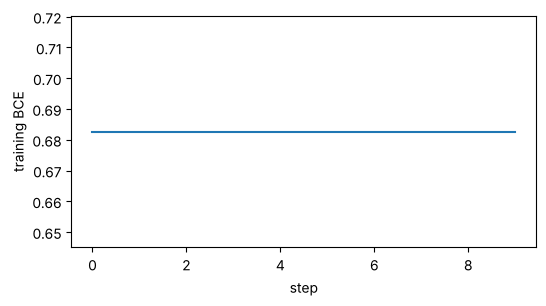

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 3))
plt.plot(losses)
plt.xlabel("step")
plt.ylabel("training BCE")
plt.show()

## Validation accuracy

Also look at the share of shots predicted "made". If it is 0 or 1, the model is constant (always miss / always made).

In [11]:
model.eval()
with torch.no_grad():
    p_va = model(X_va_t)[:, 0].numpy()  # probabilities, shape (N,)
pred = p_va > 0.5
print(f"validation accuracy {(pred == y_va).mean():.4f}   (always miss: {always_miss:.4f})")
print(f"predicted 'made' for {pred.mean():.3f} of the validation shots")

validation accuracy 0.5454   (always miss: 0.5526)
predicted 'made' for 0.049 of the validation shots


## Fold the scaling into `fc1`

The grader sends raw coordinates. If you standardised, rewrite the first layer so that it does the scaling itself. `fc1` computes W (x − μ)/σ + b. On paper, write this as W′x + b′, then overwrite `model.fc1.weight` and `model.fc1.bias` with W′ and b′.

Run this cell once: folding twice breaks the model (rerun training first). The reload check at the end tells you whether you got it right.

In [12]:
with torch.no_grad():  # we change weights by hand, so autograd must not track it
    pass  # TODO: fold mu and sd into model.fc1 (with the placeholder mu = 0, sd = 1 there is nothing to do)

## Write `submission.zip`, then load it like the grader

In [13]:
import zipfile

torch.save(model.state_dict(), SUB_DIR / "submission_dic.pth")
with zipfile.ZipFile(SUB_DIR / "submission.zip", "w") as z:
    z.write(SUB_DIR / "submission_model.py", "submission_model.py")  # top level of the zip, no folders
    z.write(SUB_DIR / "submission_dic.pth", "submission_dic.pth")

In [14]:
import tempfile

# unzip into a fresh, empty folder and load it exactly the way the grader does
check_dir = Path(tempfile.mkdtemp())
with zipfile.ZipFile(SUB_DIR / "submission.zip") as z:
    print("zip contains:", z.namelist())
    z.extractall(check_dir)
graded = load_model_class(check_dir / "submission_model.py")()
graded.load_state_dict(torch.load(check_dir / "submission_dic.pth"), strict=True)  # strict: every name and shape must match
graded.eval()
rules_ok = check_rules(graded)

with torch.no_grad():
    p_raw = graded(torch.tensor(X_va))[:, 0].numpy()  # RAW coordinates, like the grader
print(f"reloaded model on raw coordinates: validation accuracy {((p_raw > 0.5) == y_va).mean():.4f}")
print(f"max |difference| to the notebook's predictions: {np.abs(p_raw - p_va).max():.1e}")
if not rules_ok:
    print("PROBLEM: fix the FAILs above")
elif np.abs(p_raw - p_va).max() > 1e-4:
    print("PROBLEM: on raw coordinates the model predicts something else than what you validated. Did you fold the scaling into fc1?")
else:
    print("VALID: legal, and on raw coordinates it predicts exactly what you validated")

zip contains: ['submission_model.py', 'submission_dic.pth']
PASS   no nn.Sequential / ModuleList / ModuleDict
PASS   only nn.Linear and the allowed activations
PASS   no parameters or buffers outside the layers
PASS   at most 3 linear layers
PASS   at most 8 neurons per linear layer
PASS   input size 2, sizes chain up, output size 1
PASS   every linear layer used exactly once, the first module called is a linear layer
PASS   every module defined in __init__ is used in forward
PASS   every activation comes right after a linear layer
PASS   forward is only these modules, no extra maths
PASS   output shape (N, 1)
reloaded model on raw coordinates: validation accuracy 0.5454
max |difference| to the notebook's predictions: 0.0e+00
VALID: legal, and on raw coordinates it predicts exactly what you validated


Upload `kobe_submission/submission.zip` when every rule says PASS and the accuracy on raw coordinates equals your validation accuracy. Leaderboard A is computed on only about 2,500 shots, so two equally good models can differ there by ±0.01. Trust your validation number more than the leaderboard.